# Multi-Scalar Multiplication: results

This notebook presents the benchmark results for the seven MSM algorithms in the [`msm`](../msm) package:

| Family | Variants |
|---|---|
| Bos-Coster | basic, efficient |
| Bucketing | basic, interleaved, comb |
| Pippenger | standard, input partitioning |

All the algorithm code lives in the package (with tests in [`tests/`](../tests)). This notebook only **checks, loads, plots and explains** the results.

> The original dissertation notebook is kept unchanged in [`dissertation_notebook.ipynb`](dissertation_notebook.ipynb). Its bucketing and Pippenger code has a weighting bug that is fixed in the package; see the main README.

In [1]:
# Setup: works locally (run from the notebooks/ folder) and on Google Colab.
import os, subprocess, sys

REPO_URL = "https://github.com/Yousefscode/Optimising-Multi-Scalar-Multiplication.git"

if "google.colab" in sys.modules:
    if not os.path.exists("Optimising-Multi-Scalar-Multiplication"):
        subprocess.run(["git", "clone", "-q", REPO_URL], check=True)
    os.chdir("Optimising-Multi-Scalar-Multiplication")
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "ecpy"], check=True)
elif os.path.basename(os.getcwd()) == "notebooks":
    os.chdir("..")                      # work from the repository root
sys.path.insert(0, os.getcwd())

import random
import pandas as pd
import matplotlib.pyplot as plt

import msm
from msm.benchmark import load_csv, run, DISSERTATION_CASES
from msm.plots import figure

pd.set_option("display.precision", 3)
print("Algorithms:", ", ".join(msm.ALGORITHMS))

Algorithms: Bos-Coster, Bos-Coster (Efficient), Bucketing, Bucketing (Interleaved), Comb-Bucketing, Pippenger, Pippenger (Input Partitioning)


## 1. Correctness first

A benchmark only means something if every algorithm returns the right answer. Each algorithm is run on random inputs and compared with the **naive** method, which computes every $a_i P_i$ separately and adds them up.

In [2]:
curve = msm.get_curve("secp256k1")
checks = {}
for n, bits in [(5, 32), (20, 64), (50, 128), (12, 256)]:
    random.seed(f"check-{n}-{bits}")
    scalars, points = msm.generate_test_case(curve, n, bits)
    expected = msm.naive_msm(scalars, points)
    checks[f"{n} pts × {bits} bits"] = {
        name: "✅" if algo(scalars, points) == expected else "❌"
        for name, algo in msm.ALGORITHMS.items()
    }

pd.DataFrame(checks)

,5 pts × 32 bits,20 pts × 64 bits,50 pts × 128 bits,12 pts × 256 bits
Bos-Coster,✅,✅,✅,✅
Bos-Coster (Efficient),✅,✅,✅,✅
Bucketing,✅,✅,✅,✅
Bucketing (Interleaved),✅,✅,✅,✅
Comb-Bucketing,✅,✅,✅,✅
Pippenger,✅,✅,✅,✅
Pippenger (Input Partitioning),✅,✅,✅,✅


Every algorithm matches the naive result. The full test suite (`python -m pytest`) covers more sizes and edge cases, such as zero scalars, repeated scalars and a single point.

## 2. Benchmark results

The benchmark runs every algorithm on the same 12 input cases as the dissertation, recording:

- **point operations**: exact counts of additions and doublings
- **time**: median of 3 runs
- **peak memory**: measured with `tracemalloc`

A full run takes about 4 minutes, so by default this notebook loads the saved results. Set `RUN_BENCHMARK = True` to regenerate them.

In [3]:
RUN_BENCHMARK = False

if RUN_BENCHMARK:
    rows = run(DISSERTATION_CASES, trials=3)
else:
    rows = load_csv("results/benchmark_results.csv")

df = pd.DataFrame(rows)
print(f"{len(df)} results: {df['algorithm'].nunique()} algorithms × {len(df) // df['algorithm'].nunique()} cases")
df.head(7)

84 results: 7 algorithms × 12 cases


,algorithm,points,scalar_bits,time_s,peak_memory_kib,additions,doublings,total_operations
0,Bos-Coster,5,32,0.010,3.238,72,0,72
1,Bos-Coster (Efficient),5,32,0.010,3.285,72,0,72
2,Bucketing,5,32,0.024,3.254,134,33,167
3,Bucketing (Interleaved),5,32,0.022,4.215,134,33,167
4,Comb-Bucketing,5,32,0.025,5.328,91,93,184
5,Pippenger,5,32,0.016,3.559,94,31,125
6,Pippenger (Input Partitioning),5,32,0.023,3.855,100,102,202


### 2.1 Point operations vs number of points

**What it shows:** total point additions and doublings as the number of points grows from 5 to 100, with 32-bit scalars. Both axes are logarithmic.

**Takeaway:**
- **Bos-Coster needs the fewest operations at every size.** Its two variants do identical work, so their lines overlap.
- Bucketing and Pippenger are identical at 20 points, because Pippenger's window $c = \log_2 20 \approx 4$ equals bucketing's fixed 4 bits.
- At 50 and 100 points, Pippenger's wider window (6–7 bits) costs more than it saves, so it falls behind fixed 4-bit bucketing.
- Input partitioning is clearly the worst.

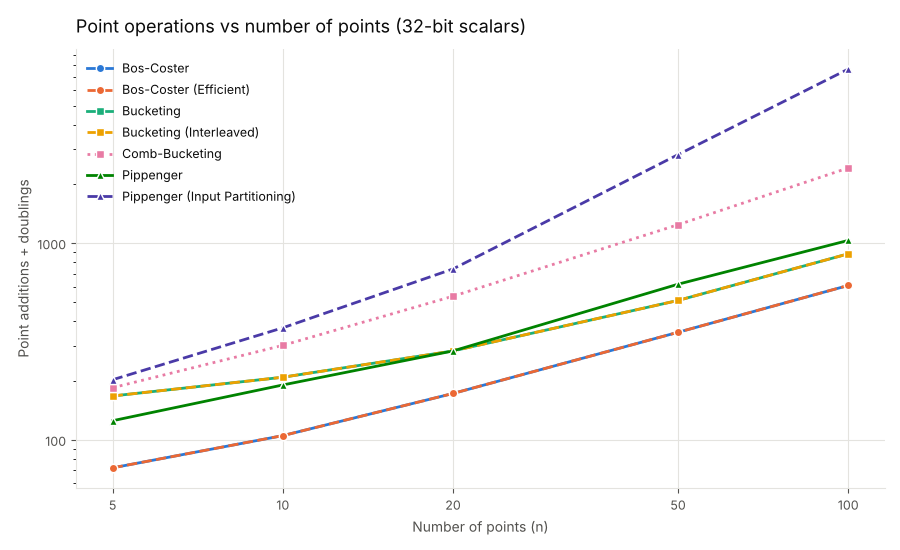

In [4]:
figure(rows, "ops_vs_points")
plt.show()

### 2.2 Execution time vs number of points

**What it shows:** median wall-clock time for the same inputs.

**Takeaway:** time follows the operation counts closely. In pure Python each point operation costs about the same, so the ranking does not change: **Bos-Coster is fastest in every case.** Absolute times are slow because ECPy is pure Python, so read this chart for the comparison only.

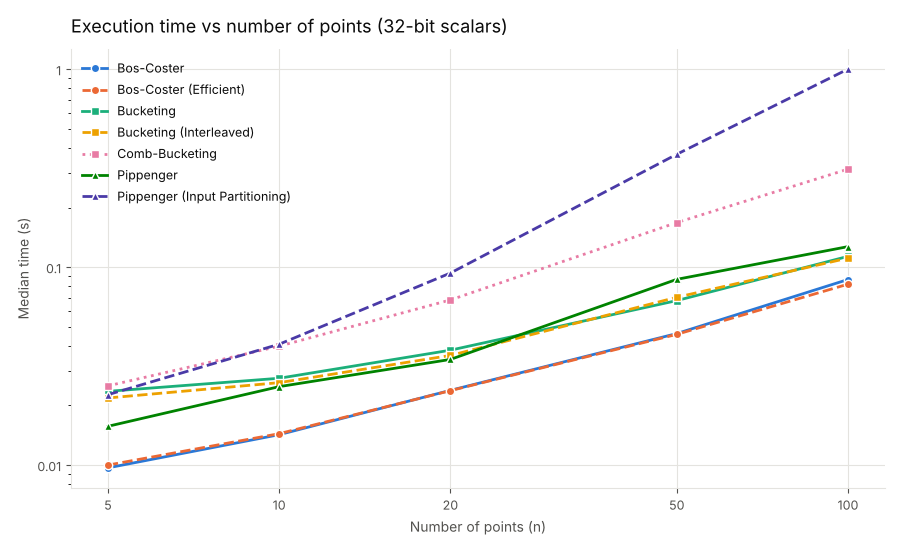

In [5]:
figure(rows, "time_vs_points")
plt.show()

### 2.3 Point operations vs scalar bit length

**What it shows:** a fixed 20 points with scalars from 8 to 128 bits.

**Takeaway:** cost grows roughly in proportion to the bit length for every algorithm, because each extra window or reduction step costs the same. The ranking stays the same at every bit length. Bucketing and Pippenger overlap here because both use a 4-bit window at $n = 20$.

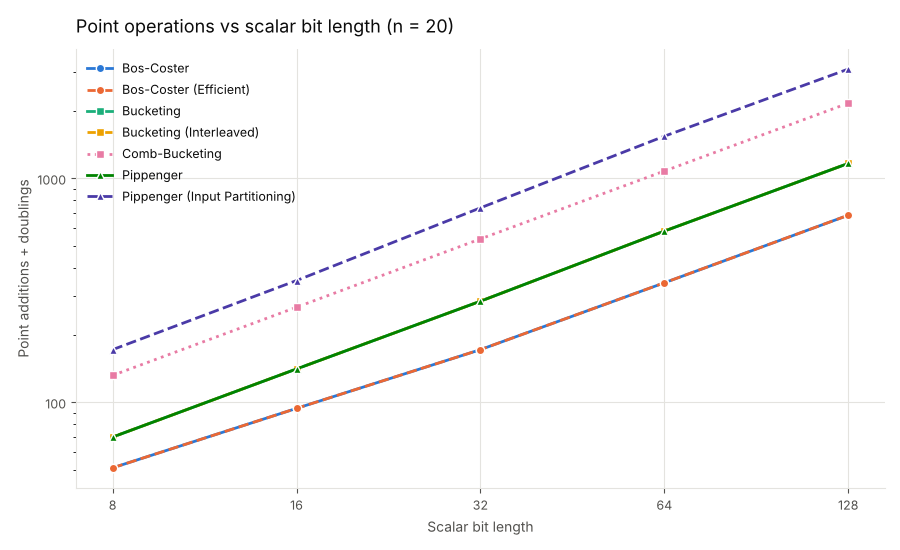

In [6]:
figure(rows, "ops_vs_bits")
plt.show()

### 2.4 Operations per point

**What it shows:** total operations divided by the number of points, which measures how well each algorithm spreads its fixed costs.

**Takeaway:**
- For Bos-Coster, bucketing, Pippenger and comb-bucketing, the cost per point **falls** as $n$ grows, because fixed costs (doublings, bucket sums) are shared by more points. Bos-Coster goes from about 14 to about 6 operations per point.
- Input partitioning goes the other way. Each small chunk pays the full bucket overhead again, so its cost per point rises with $n$.

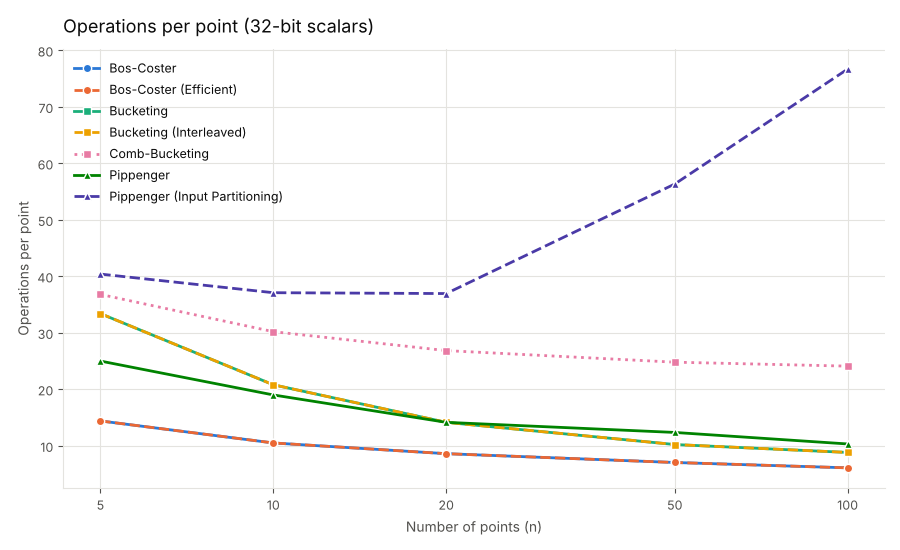

In [7]:
figure(rows, "ops_per_point")
plt.show()

### 2.5 Peak memory

**What it shows:** peak Python memory allocation during one run.

**Takeaway:**
- Comb-bucketing uses the most memory, because it stores shifted copies of every point.
- Bos-Coster's working list grows with $n$, so at 50 points and above it uses more than bucketing and Pippenger, which only keep their buckets.
- All values are small, and these are Python object sizes, not the costs of an optimised implementation.

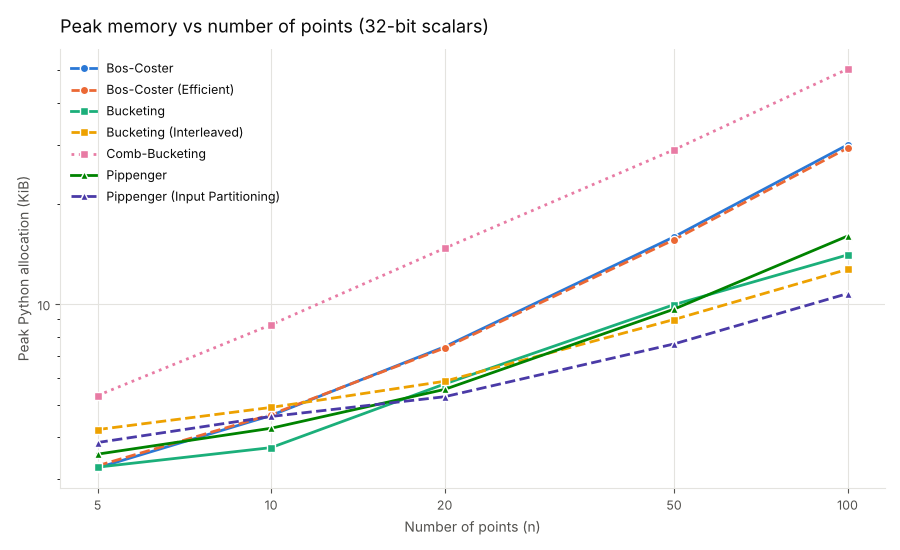

In [8]:
figure(rows, "memory_vs_points")
plt.show()

## 3. Who wins each case?

Total point operations for every case. The last column names the algorithm with the fewest operations. The two Bos-Coster variants do exactly the same work, so they always tie, and the table names the first.

In [9]:
ops = df.pivot_table(index=["points", "scalar_bits"], columns="algorithm",
                     values="total_operations", aggfunc="first")[list(msm.ALGORITHMS)]
ops["fewest operations"] = ops.idxmin(axis=1)
ops

algorithm           Bos-Coster  ...  fewest operations
points scalar_bits              ...                   
5      16                   37  ...         Bos-Coster
       32                   72  ...         Bos-Coster
10     32                  105  ...         Bos-Coster
20     8                    51  ...         Bos-Coster
       16                   94  ...         Bos-Coster
       32                  172  ...         Bos-Coster
       64                  342  ...         Bos-Coster
       128                 685  ...         Bos-Coster
50     32                  352  ...         Bos-Coster
       128                1356  ...         Bos-Coster
100    32                  609  ...         Bos-Coster
       256                4640  ...         Bos-Coster

[12 rows x 8 columns]

## 4. Beyond the dissertation's grid

Pippenger's advantage is asymptotic, so does it overtake at larger inputs? Here are three representative algorithms at 200 and 500 points with 256-bit scalars, counting operations only (about 30 seconds).

In [10]:
contenders = {
    "Bos-Coster (Efficient)": msm.bos_coster_efficient,
    "Bucketing (Interleaved)": msm.interleaved_bucketing,
    "Pippenger": msm.pippenger,
}
larger = {}
for n in (200, 500):
    random.seed(f"large-{n}")
    scalars, points = msm.generate_test_case(curve, n, 256)
    expected = msm.naive_msm(scalars, points)
    larger[n] = {}
    for name, algo in contenders.items():
        with msm.count_operations() as counted:
            assert algo(scalars, points) == expected
        larger[n][name] = counted["additions"] + counted["doublings"]

pd.DataFrame(larger).rename(columns=lambda n: f"{n} points × 256 bits")

,200 points × 256 bits,500 points × 256 bits
Bos-Coster (Efficient),8123,17372
Bucketing (Interleaved),13128,31147
Pippenger,14706,28972


Bos-Coster still needs the fewest operations, and Pippenger has overtaken fixed-window bucketing by 500 points. Pippenger is designed for the much larger inputs used in zero-knowledge provers (often millions of points), which are far beyond what pure Python can benchmark here.

## Conclusions

1. **Bos-Coster** was the fastest and used the fewest point operations in all 12 benchmark cases (up to 100 points). It also needed the fewest operations in the extra check at 500 points.
2. **Bucketing** with a fixed 4-bit window is a simple, predictable runner-up at these sizes.
3. **Pippenger**, with $c = \log_2 n$, chooses windows that are too wide for small $n$. It starts to beat fixed bucketing in the hundreds of points, and its asymptotic advantage matters at much larger scales.
4. **Comb-bucketing** only pays off when its shifted points can be **precomputed** (fixed-base settings). **Input partitioning** with $\log_2 n$-sized chunks is not worth it at these sizes.